# Guardian VADER · 주간 WSI 검토
확정 전처리 `guardian_text_v2_final`을 보존하고 `text_sentiment`를 VADER 3.3.2로 평가했다.
**Broad = primary, strict = robustness.** 두 표본을 합친 지표는 만들지 않는다.

이 노트북은 저장 결과만 읽는다. 모델 재실행, 전처리 변경, API 요청, FGI 병합·시차·수익률 분석은 수행하지 않는다.

In [1]:
from pathlib import Path
import json,sys
BASE=Path.cwd().resolve()
if not (BASE/"guardian_sentiment_analysis.py").exists():
    BASE=BASE/"midterm paper"
sys.path.insert(0,str(BASE/".packages"))
import pandas as pd
from IPython.display import display,Markdown,Image
RESULTS=BASE/"results/guardian_sentiment"
FIGURES=BASE/"figures/guardian_sentiment"
pd.set_option("display.max_colwidth",160)
model=json.loads((RESULTS/"sentiment_model.json").read_text(encoding="utf-8"))
print(model["package"],model["version"],model["input"],model["input_policy"])
print("Inclusive thresholds:",model["negative_threshold_inclusive"],model["positive_threshold_inclusive"])
print("Frozen policy SHA-256:",model["input_policy_sha256"])

vaderSentiment 3.3.2 text_sentiment guardian_text_v2_final
Inclusive thresholds: -0.05 0.05
Frozen policy SHA-256: 2874fd2b32c45097b161ccc62931a899777a0c7b9711d98efd587d7d1b1dff5d


## 1. 기사별 점수·클래스 분포
std는 ddof=1, 첨도는 Fisher 초과첨도(정규분포 0)이다. 분류를 수동 보정하지 않았다.

,query_strategy,article_count,mean_compound,median_compound,std_compound,min_compound,max_compound,skewness,excess_kurtosis,pearson_kurtosis,positive_count,positive_share,neutral_count,neutral_share,negative_count,negative_share
0,broad_business_control,5054,-0.078187,-0.0516,0.519198,-0.9705,0.9485,0.100755,-1.165592,1.834408,2009,0.397507,517,0.102295,2528,0.500198
1,anchors_stock_market_tag,2512,-0.093187,-0.0772,0.520303,-0.9705,0.9485,0.137575,-1.146080,1.853920,955,0.380175,261,0.103901,1296,0.515924


,query_strategy,sentiment_class,count,share
0,broad_business_control,positive,2009,0.397507
1,broad_business_control,neutral,517,0.102295
2,broad_business_control,negative,2528,0.500198
3,anchors_stock_market_tag,positive,955,0.380175
4,anchors_stock_market_tag,neutral,261,0.103901
5,anchors_stock_market_tag,negative,1296,0.515924


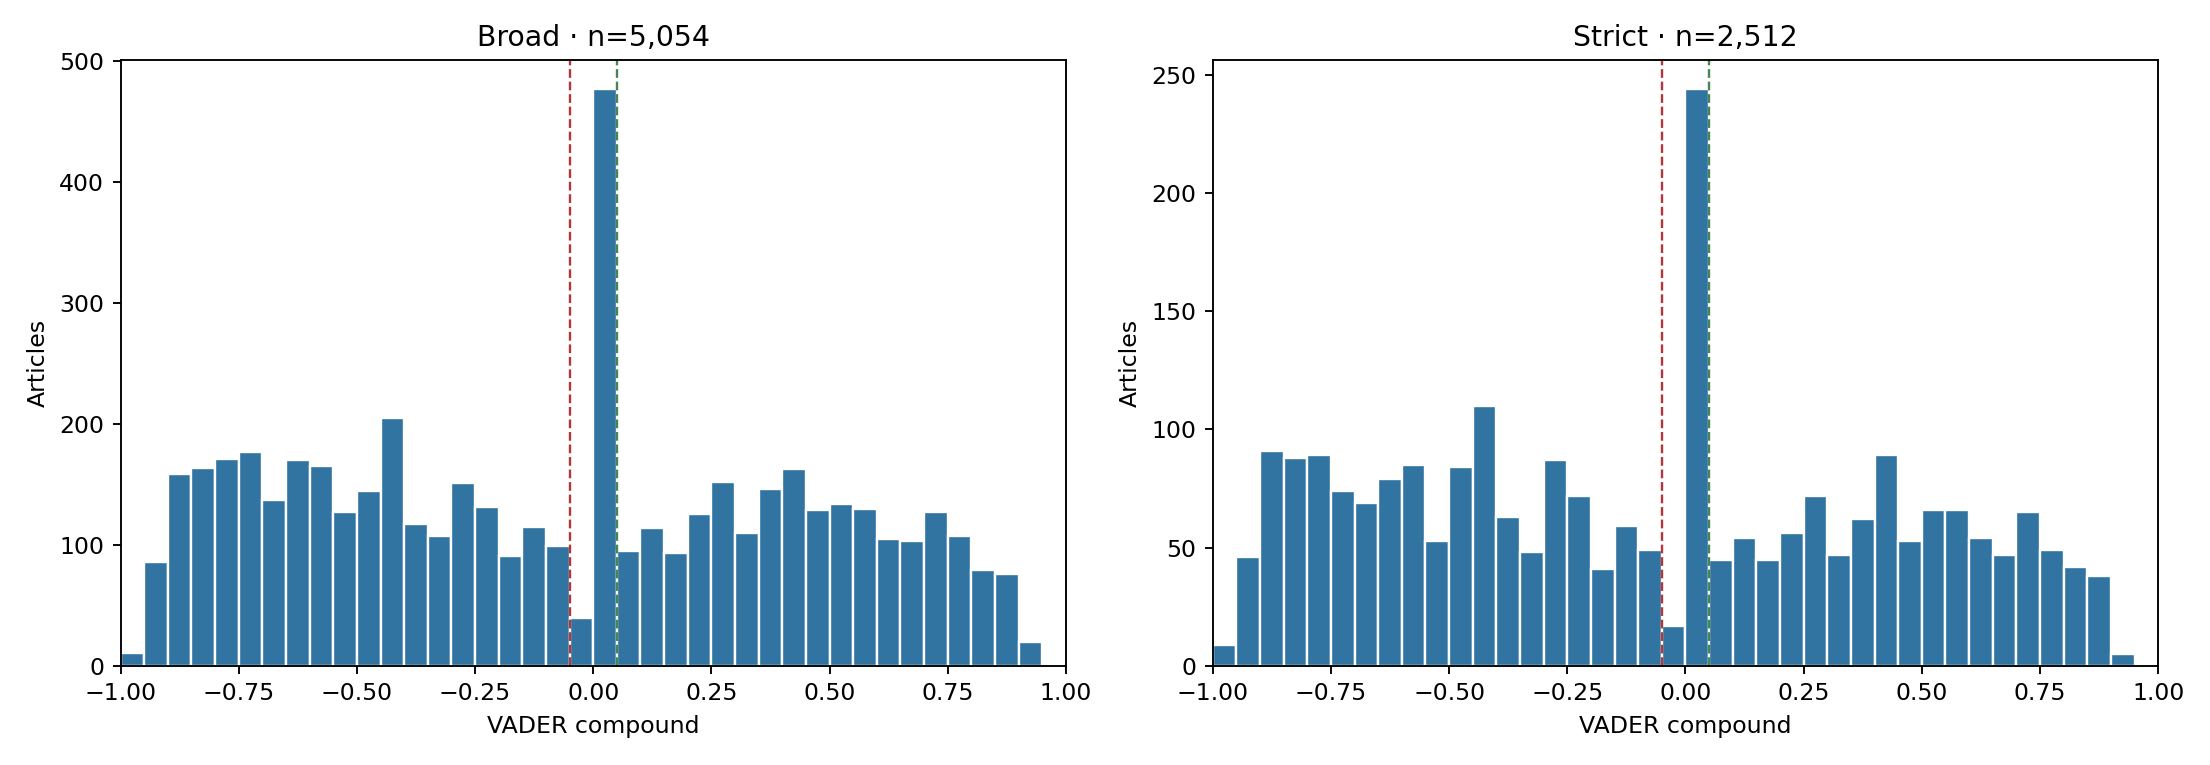

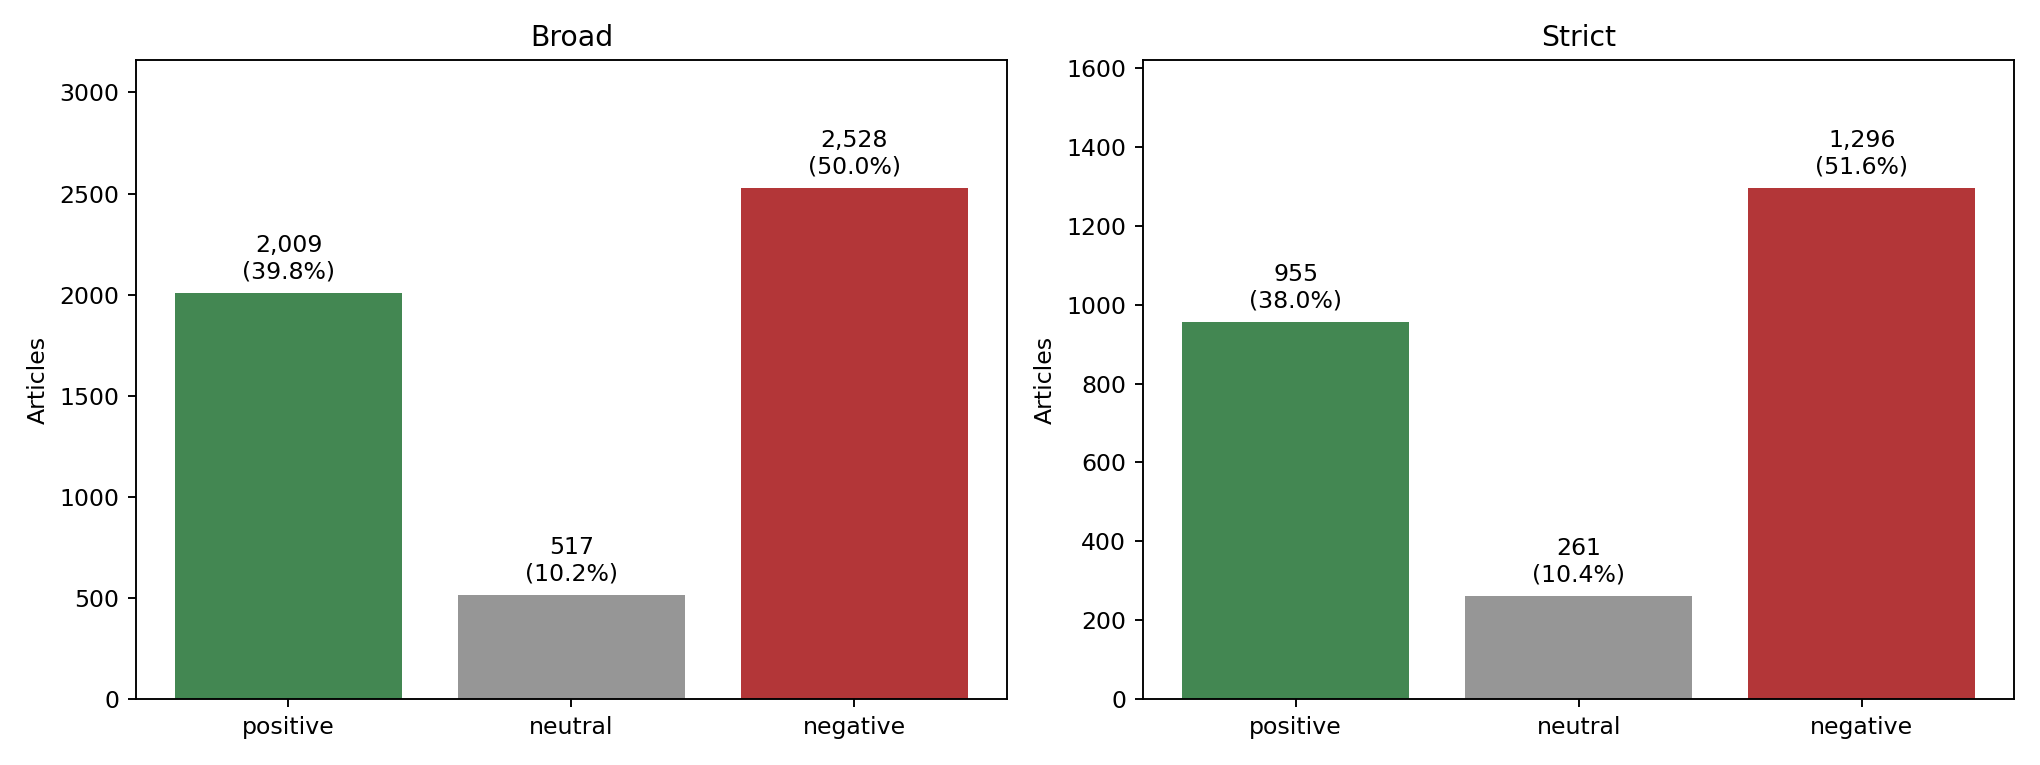

In [2]:
display(pd.read_csv(RESULTS/"article_descriptive_statistics.csv"))
display(pd.read_csv(RESULTS/"sentiment_class_distribution.csv"))
display(Image(filename=str(FIGURES/"compound_score_histogram.png"),width=1100))
display(Image(filename=str(FIGURES/"sentiment_class_distribution.png"),width=1100))

## 2. 주간 감성과 두 WSI
뉴욕 월~일 주를 보존한다. 경계의 불완전 주를 포함하면 513주, 완전한 주는 512주이다.
기사 0건인 주는 비율·감성·지표·구간이 결측이며 보간하지 않았다.

`WSI_count = 50 × [1 + (positive_count − negative_count) / article_count]`가 주 명세다.
`WSI_continuous = 50 × (1 + mean_compound)`는 연속 점수 강건성 명세다.

In [3]:
broad=pd.read_csv(RESULTS/"weekly_broad_sentiment.csv")
strict=pd.read_csv(RESULTS/"weekly_strict_sentiment.csv")
display(broad.head(10))
display(strict.loc[strict.article_count.eq(0)])
stats=pd.read_csv(RESULTS/"weekly_descriptive_statistics.csv")
display(stats.loc[stats.scope.eq("complete_weeks")])
display(pd.read_csv(RESULTS/"broad_strict_wsi_comparison.csv"))

,week_start,query_strategy,week_id,week_end,days_observed,is_complete_week,article_count,positive_count,positive_share,neutral_count,...,WSI_continuous,se_balance,se_WSI_count,WSI_count_ci95_low,WSI_count_ci95_high,small_sample_lt3,small_sample_lt5,unanimous_sentiment_week,approx_interval_degenerate,interval_method
0,2016-12-26,broad_business_control,2016-W52,2017-01-01,1,False,0,0,NaN,0,...,NaN,NaN,NaN,NaN,NaN,True,True,False,False,multinomial plug-in normal approximation; 1.96; no independence guarantee
1,2017-01-02,broad_business_control,2017-W01,2017-01-08,7,True,5,4,0.800000,0,...,68.287000,0.357771,17.888544,44.938454,115.061546,False,False,False,False,multinomial plug-in normal approximation; 1.96; no independence guarantee
2,2017-01-09,broad_business_control,2017-W02,2017-01-15,7,True,8,5,0.625000,0,...,49.861250,0.342327,17.116330,28.951993,96.048007,False,False,False,False,multinomial plug-in normal approximation; 1.96; no independence guarantee
3,2017-01-16,broad_business_control,2017-W03,2017-01-22,7,True,14,9,0.642857,1,...,57.866429,0.239198,11.959906,44.415727,91.298559,False,False,False,False,multinomial plug-in normal approximation; 1.96; no independence guarantee
4,2017-01-23,broad_business_control,2017-W04,2017-01-29,7,True,10,6,0.600000,1,...,55.102000,0.284605,14.230249,37.108711,92.891289,False,False,False,False,multinomial plug-in normal approximation; 1.96; no independence guarantee
5,2017-01-30,broad_business_control,2017-W05,2017-02-05,7,True,7,4,0.571429,0,...,51.390000,0.374088,18.704391,20.482252,93.803463,False,False,False,False,multinomial plug-in normal approximation; 1.96; no independence guarantee
6,2017-02-06,broad_business_control,2017-W06,2017-02-12,7,True,8,1,0.125000,0,...,27.781250,0.233854,11.692679,-10.417651,35.417651,False,False,False,False,multinomial plug-in normal approximation; 1.96; no independence guarantee
7,2017-02-13,broad_business_control,2017-W07,2017-02-19,7,True,10,7,0.700000,0,...,58.998500,0.289828,14.491377,41.596902,98.403098,False,False,False,False,multinomial plug-in normal approximation; 1.96; no independence guarantee
8,2017-02-20,broad_business_control,2017-W08,2017-02-26,7,True,7,2,0.285714,1,...,47.130000,0.332847,16.642354,3.095273,68.333299,False,False,False,False,multinomial plug-in normal approximation; 1.96; no independence guarantee
9,2017-02-27,broad_business_control,2017-W09,2017-03-05,7,True,11,7,0.636364,0,...,55.993182,0.290081,14.504073,35.208380,92.064347,False,False,False,False,multinomial plug-in normal approximation; 1.96; no independence guarantee


,week_start,query_strategy,week_id,week_end,days_observed,is_complete_week,article_count,positive_count,positive_share,neutral_count,...,WSI_continuous,se_balance,se_WSI_count,WSI_count_ci95_low,WSI_count_ci95_high,small_sample_lt3,small_sample_lt5,unanimous_sentiment_week,approx_interval_degenerate,interval_method
0,2016-12-26,anchors_stock_market_tag,2016-W52,2017-01-01,1,False,0,0,NaN,0,...,NaN,NaN,NaN,NaN,NaN,True,True,False,False,multinomial plug-in normal approximation; 1.96; no independence guarantee
16,2017-04-17,anchors_stock_market_tag,2017-W16,2017-04-23,7,True,0,0,NaN,0,...,NaN,NaN,NaN,NaN,NaN,True,True,False,False,multinomial plug-in normal approximation; 1.96; no independence guarantee
56,2018-01-22,anchors_stock_market_tag,2018-W04,2018-01-28,7,True,0,0,NaN,0,...,NaN,NaN,NaN,NaN,NaN,True,True,False,False,multinomial plug-in normal approximation; 1.96; no independence guarantee
119,2019-04-08,anchors_stock_market_tag,2019-W15,2019-04-14,7,True,0,0,NaN,0,...,NaN,NaN,NaN,NaN,NaN,True,True,False,False,multinomial plug-in normal approximation; 1.96; no independence guarantee
146,2019-10-14,anchors_stock_market_tag,2019-W42,2019-10-20,7,True,0,0,NaN,0,...,NaN,NaN,NaN,NaN,NaN,True,True,False,False,multinomial plug-in normal approximation; 1.96; no independence guarantee
252,2021-10-25,anchors_stock_market_tag,2021-W43,2021-10-31,7,True,0,0,NaN,0,...,NaN,NaN,NaN,NaN,NaN,True,True,False,False,multinomial plug-in normal approximation; 1.96; no independence guarantee
316,2023-01-16,anchors_stock_market_tag,2023-W03,2023-01-22,7,True,0,0,NaN,0,...,NaN,NaN,NaN,NaN,NaN,True,True,False,False,multinomial plug-in normal approximation; 1.96; no independence guarantee
338,2023-06-19,anchors_stock_market_tag,2023-W25,2023-06-25,7,True,0,0,NaN,0,...,NaN,NaN,NaN,NaN,NaN,True,True,False,False,multinomial plug-in normal approximation; 1.96; no independence guarantee
386,2024-05-20,anchors_stock_market_tag,2024-W21,2024-05-26,7,True,0,0,NaN,0,...,NaN,NaN,NaN,NaN,NaN,True,True,False,False,multinomial plug-in normal approximation; 1.96; no independence guarantee


,scope,query_strategy,metric,calendar_weeks,valid_weeks,missing_weeks,mean,median,std,min,max,weeks_lt3_articles,weeks_lt5_articles,degenerate_intervals,intervals_outside_0_100
0,complete_weeks,broad_business_control,WSI_count,512,512,0,45.395075,45.000000,18.333223,0.000,100.000,0,18,4,115
1,complete_weeks,broad_business_control,WSI_continuous,512,512,0,46.317642,46.801643,10.377640,17.068,73.183,0,18,4,115
2,complete_weeks,anchors_stock_market_tag,WSI_count,512,504,8,43.634107,41.666667,26.321112,0.000,100.000,71,251,76,288
3,complete_weeks,anchors_stock_market_tag,WSI_continuous,512,504,8,45.527815,45.810500,14.763565,8.875,88.250,71,251,76,288


,scope,metric,paired_valid_weeks,broad_strict_pearson_correlation
0,complete_weeks,WSI_count,504,0.682631
1,complete_weeks,WSI_continuous,504,0.716923
2,all_calendar_weeks,WSI_count,504,0.682631
3,all_calendar_weeks,WSI_continuous,504,0.716923


## 3. 주별 지표와 근사 표본 구간
Count 지표 그림의 음영은 multinomial plug-in SE에 기반한 ±1.96 SE 구간이다.
독립성을 보장하지 않으며, 적은 기사 수·같은 감성 범주만 관찰된 주에서는 과소 추정할 수 있다.
0폭 구간은 확실성의 증거가 아니다. 구간은 식 그대로 저장해 0~100 밖으로 나갈 수 있다.
Broad와 strict에는 중첩 기사가 있다. 두 표본을 독립 표본으로 해석하지 않는다.

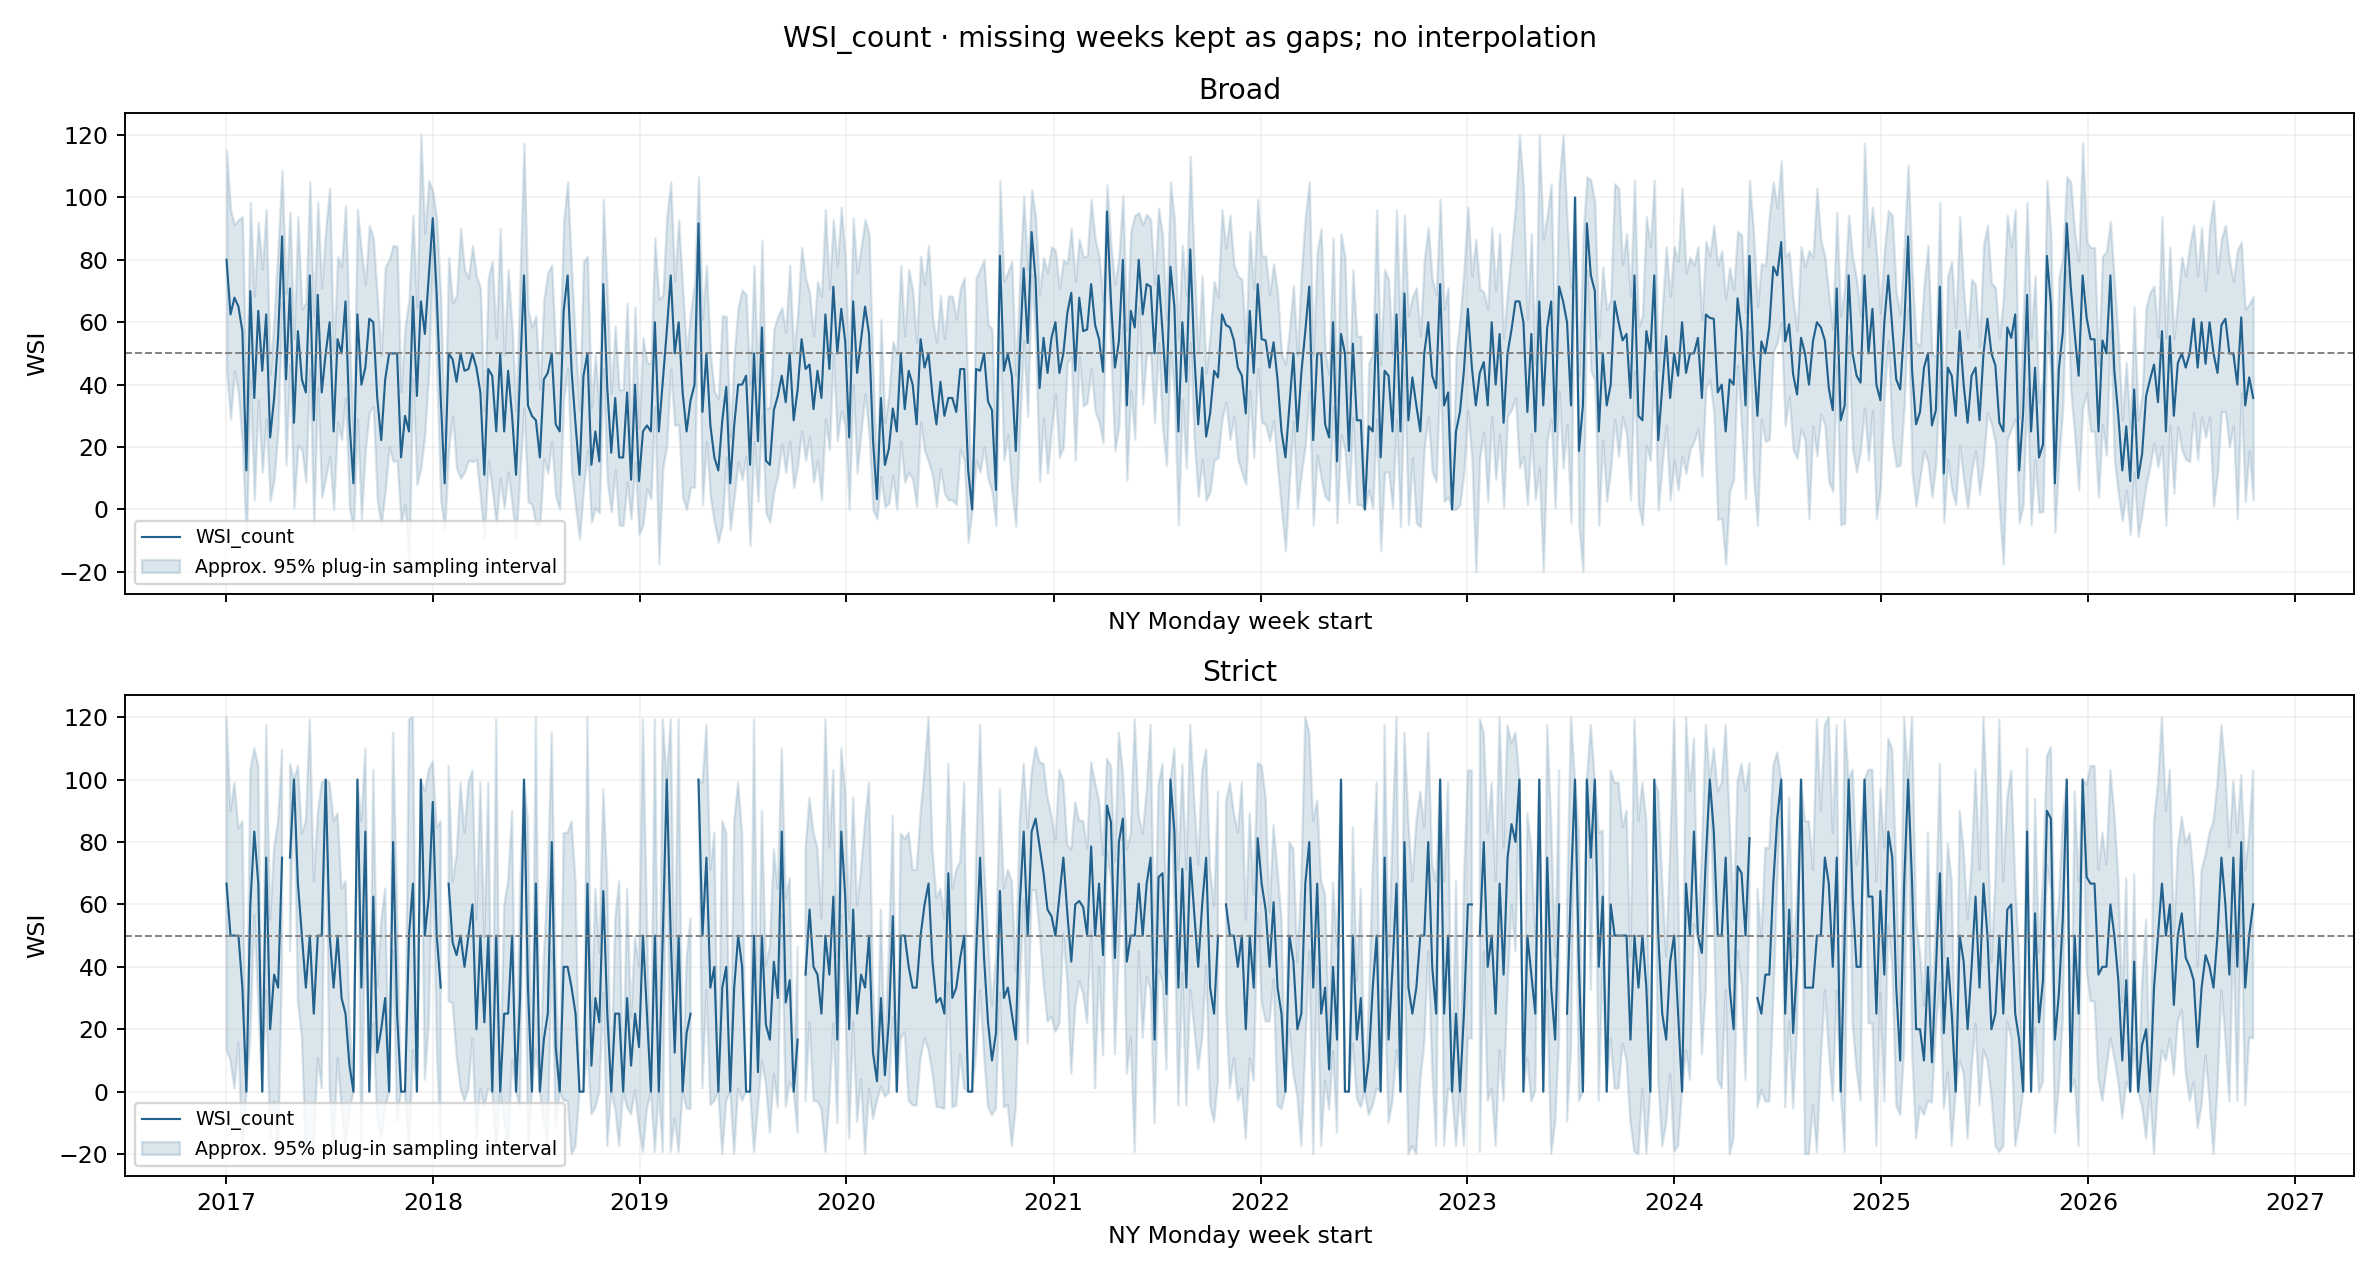

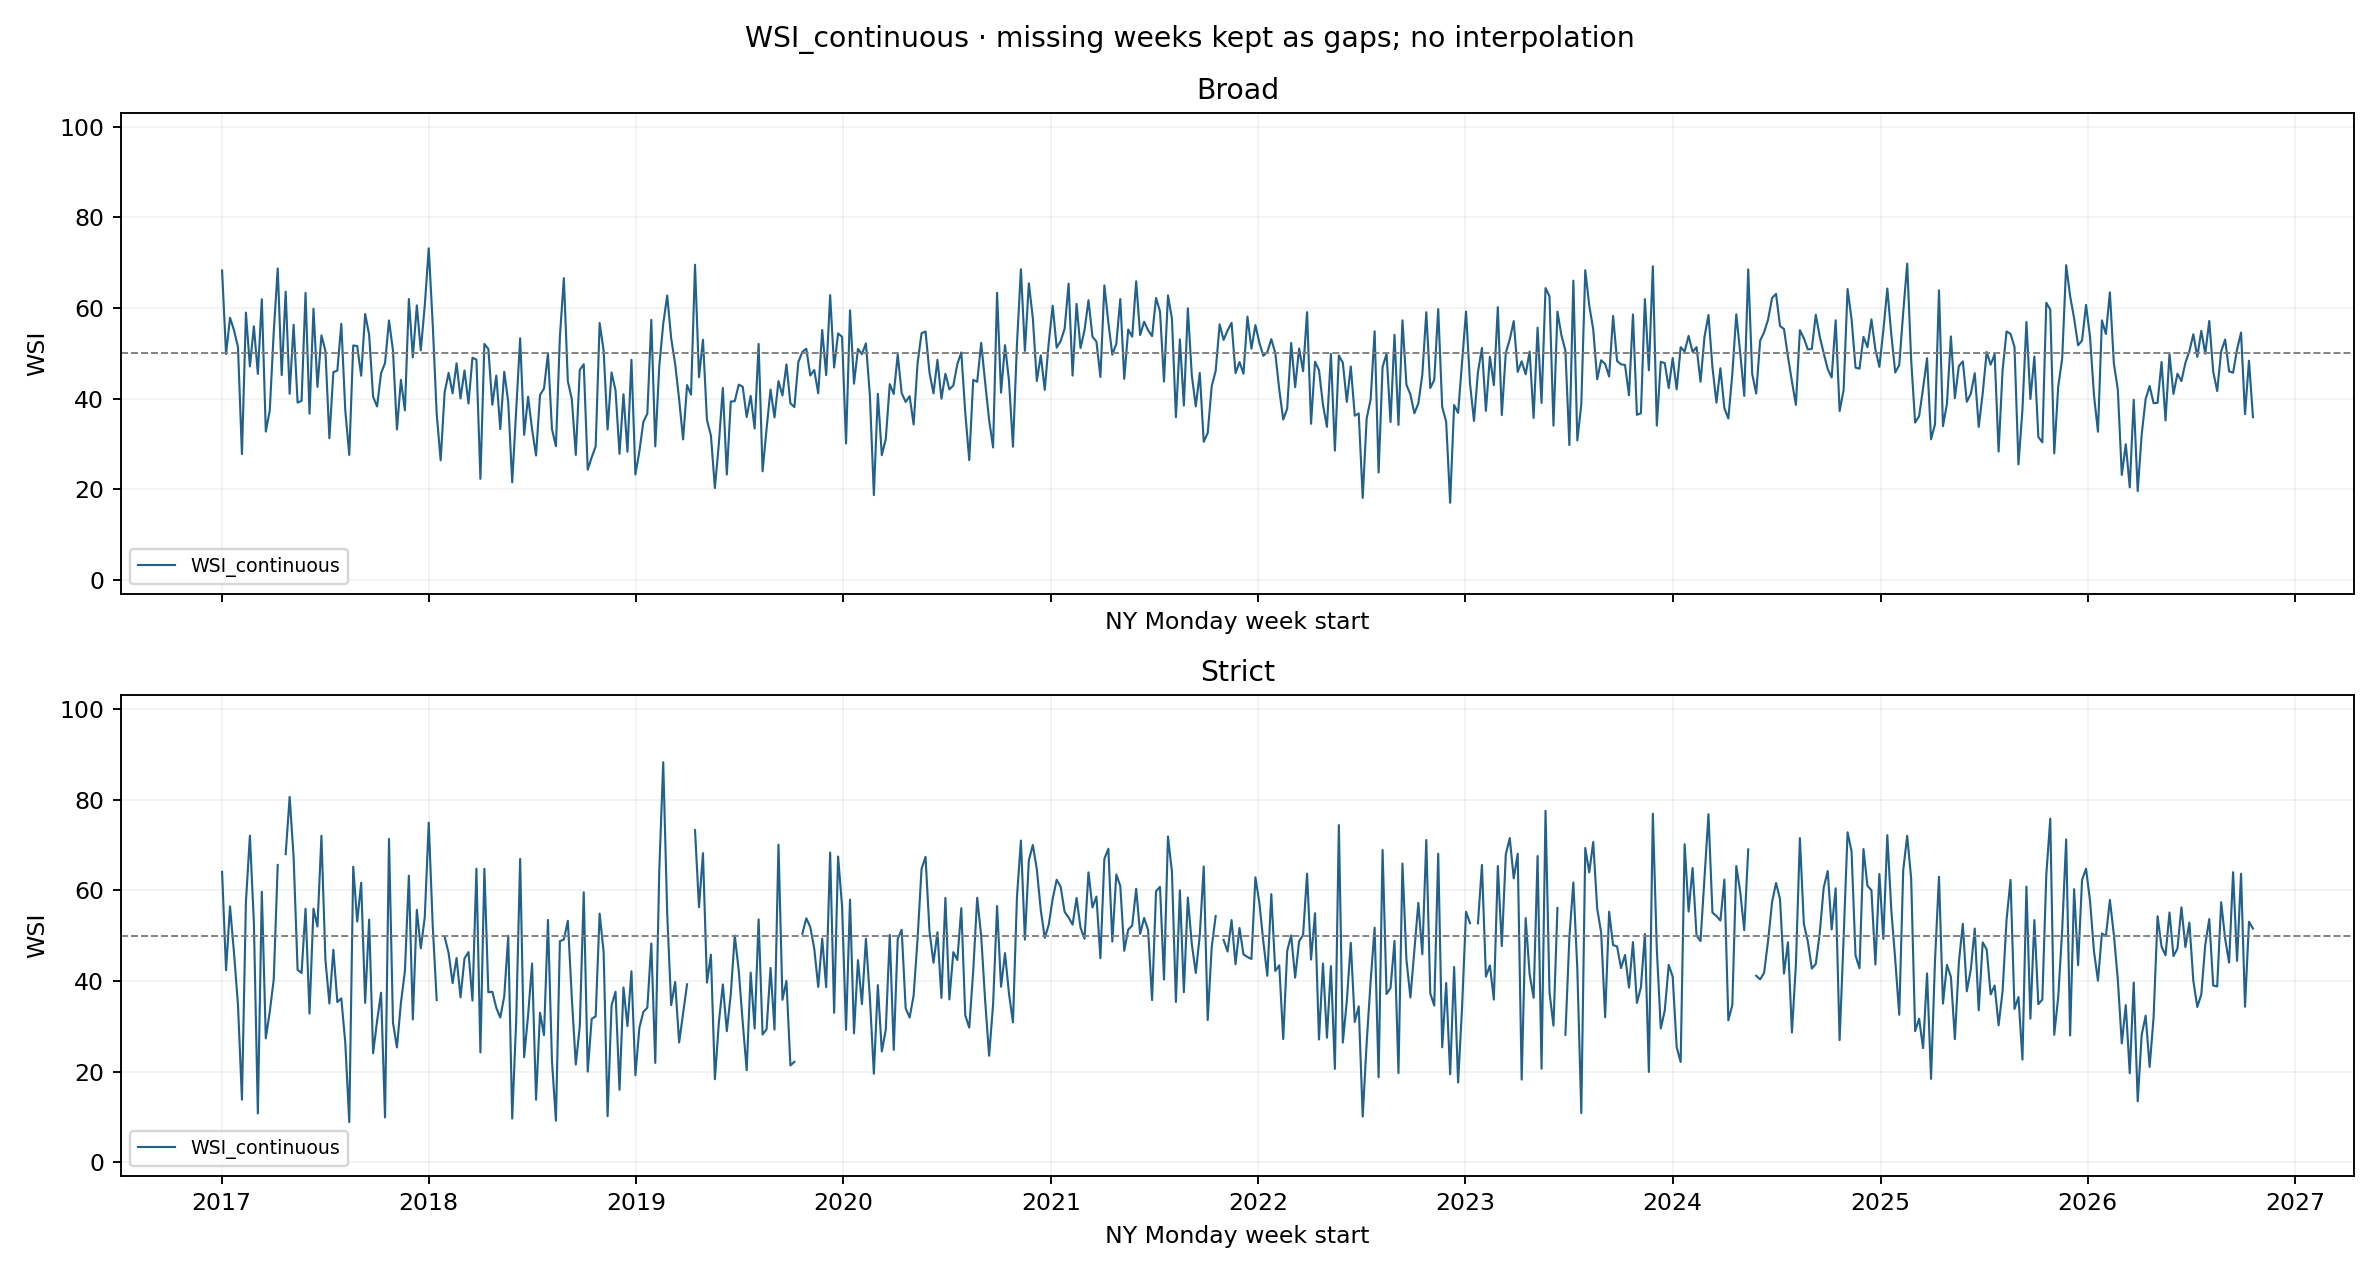

,query_strategy,weeks_lt3_articles,weeks_lt5_articles,degenerate_intervals,intervals_outside_0_100
0,broad_business_control,0,18,4,115
2,anchors_stock_market_tag,71,251,76,288


In [4]:
display(Image(filename=str(FIGURES/"weekly_wsi_count.png"),width=1200))
display(Image(filename=str(FIGURES/"weekly_wsi_continuous.png"),width=1200))
display(stats.loc[stats.scope.eq("complete_weeks") & stats.metric.eq("WSI_count"),
    ["query_strategy","weeks_lt3_articles","weeks_lt5_articles","degenerate_intervals","intervals_outside_0_100"]])

## 4. 오류 검사 후보 · 자동 재분류 없음
강한 긍정·부정, 중립 근처, 욕설·슬랭(관측된 경우), 방향 단어와 점수의 의심 조합을 검사한다.
휴리스틱은 오류를 확정하지 않는다. 범용 VADER의 금융 표현·풍자·밈 처리 능력을 가정하지 않는다.
`manual_error_assessment`는 비워 두었다.

In [5]:
display(pd.read_csv(RESULTS/"inspection_candidate_inventory.csv"))
sample=pd.read_csv(RESULTS/"vader_inspection_sample.csv")
print("Inspection articles:",len(sample))
display(sample[["title","text_sentiment","compound","sentiment_class","inspection_reasons","manual_error_assessment"]].head(20))

,inspection_category,candidate_articles,sampled_articles,selection_rule,random_seed
0,strongly_positive,298,12,compound >= 0.75,42
1,strongly_negative,612,12,compound <= -0.75,43
2,near_neutral,732,12,"abs(compound) <= 0.10, including threshold-adjacent labels",44
3,profanity_or_slang,0,0,\b(?:fuck(?:ing|ed)?|shit|bullshit|bastard|damn|crap|fomo|yolo|stonks|hodl|tendies|rekt)\b|diamond hands|to the moon,45
4,potential_suspicious_classification,389,20,"direction-word heuristic vs zero/opposite compound; candidate only, not a verified error",46


Inspection articles: 56


,title,text_sentiment,compound,sentiment_class,inspection_reasons,manual_error_assessment
0,"Dow Jones industrial average surpasses 20,000 to record high","Dow Jones industrial average surpasses 20,000 to record high The Dow, which tracks the largest publicly owned companies in the US, finally breaks record aft...",0.0000,neutral,potential_suspicious_classification,NaN
1,Amazon founder Jeff Bezos – briefly – becomes world's richest man,Amazon founder Jeff Bezos – briefly – becomes world's richest man Share price jump of 40% in 2017 made founder worth $91bn – for a short while leapfrogging ...,0.8020,positive,strongly_positive,NaN
2,More than a million people join ranks of very wealthy after stock markets boom,More than a million people join ranks of very wealthy after stock markets boom Number of high net worth individuals – with free assets of more than $1m – gr...,0.9259,positive,strongly_positive,NaN
3,European stock markets recover after sharp losses,European stock markets recover after sharp losses FTSE gained nearly 2% but Dow Jones recovery failed to last with index falling back by close to end more t...,-0.7506,negative,strongly_negative,NaN
4,Fed chair Jerome Powell softens line on interest rate rises after Trump attack,"Fed chair Jerome Powell softens line on interest rate rises after Trump attack Rates currently ‘just below’ range Fed officials consider neutral, Powell say...",-0.0258,neutral,near_neutral,NaN
5,Levi Strauss seeks $6.2bn valuation in stock market listing,Levi Strauss seeks $6.2bn valuation in stock market listing Jeans maker plans to return public ownership after three decades as a private company,0.0000,neutral,near_neutral,NaN
6,Unhappy campers? Tents and other gear close to selling out in UK holiday boom,Unhappy campers? Tents and other gear close to selling out in UK holiday boom Sports retailer Decathlon says sales of family tents are up more than 70% on p...,-0.0258,neutral,near_neutral,NaN
7,GSK shares surge as US judge dismisses Zantac cancer claims,"GSK shares surge as US judge dismisses Zantac cancer claims About 50,000 federal lawsuits claimed that the best-selling heartburn drug had led to cancer",-0.8481,negative,strongly_negative,NaN
8,‘White knuckle’ week for tech titans as shares and fortunes fall,‘White knuckle’ week for tech titans as shares and fortunes fall Nine of world’s 10 richest billionaires see wealth dented as rising interest rates spur sel...,0.8957,positive,strongly_positive,NaN
9,Richard Branson’s Virgin Orbit files for bankruptcy after failing to find funding,Richard Branson’s Virgin Orbit files for bankruptcy after failing to find funding California-based company forced to cut 85% of workforce after struggling t...,-0.8316,negative,strongly_negative,NaN


## 5. 보존·검증·중단 지점
전체 기사 원본 열·확정 정책 보존, 전 기사 재채점 교차 검증, 집계·수식·결측 확인. FGI·시장 자료는 읽지 않았다.

In [6]:
print((RESULTS/"independent_validation.json").read_text(encoding="utf-8"))
display(Markdown((BASE/"GUARDIAN_SENTIMENT_REVIEW.md").read_text(encoding="utf-8")))

{
  "status": "passed",
  "article_records_verified": 5265,
  "all_original_columns_and_types_unchanged": true,
  "VADER_recomputed_for_every_article": true,
  "threshold_boundary_and_empty_singleton_week_tests": "passed",
  "NY_week_assignment_verified": true,
  "weekly_counts_shares_compound_WSI_and_intervals_independently_verified": true,
  "article_moments_and_weekly_descriptives_verified": true,
  "strategy_correlations_verified": true,
  "empty_complete_weeks": {
    "broad_business_control": 0,
    "anchors_stock_market_tag": 8
  },
  "inspection_sample_articles_verified": 56,
  "frozen_policy_and_input_hashes_unchanged": true,
  "FGI_or_market_data_used": false
}



# Guardian VADER 및 주간 WSI 진단

VADER 3.3.2를 확정된 `guardian_text_v2_final`의 `text_sentiment` 전체에 기사별로 한 번씩 적용했다.
전처리 정책, text_raw/text_sentiment/text_clean, 원본 메타데이터와 소속 플래그는 수정하지 않았다.
동일 기사에는 한 점수만 부여하고 두 전략의 소속을 유지한다. 파일럿 relevance 라벨은 사용하지 않았다.

물리적 기사 5,265건; broad 5,054건; strict 2,512건; 중첩 2,301건.

## 기사별 분포

positive: compound >= 0.05; negative: compound <= -0.05; 나머지는 neutral. 수동 보정은 없다.
표준편차는 ddof=1, 왜도는 pandas 보정 표본 왜도, 첨도는 Fisher 초과첨도(정규분포 0)이다. Pearson 첨도도 CSV에 병기했다.

| query_strategy | article_count | mean_compound | median_compound | std_compound | min_compound | max_compound | skewness | excess_kurtosis |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| broad_business_control | 5054 | -0.0782 | -0.0516 | 0.5192 | -0.9705 | 0.9485 | 0.1008 | -1.1656 |
| anchors_stock_market_tag | 2512 | -0.0932 | -0.0772 | 0.5203 | -0.9705 | 0.9485 | 0.1376 | -1.1461 |

| query_strategy | positive_count | positive_share | neutral_count | neutral_share | negative_count | negative_share |
| --- | --- | --- | --- | --- | --- | --- |
| broad_business_control | 2009 | 0.3975 | 517 | 0.1023 | 2528 | 0.5002 |
| anchors_stock_market_tag | 955 | 0.3802 | 261 | 0.1039 | 1296 | 0.5159 |

## 주간 구조와 두 WSI

America/New_York 월요일~일요일 주를 그대로 사용한다. 513개 경계 포함 주 중 완전한 주는 512개이다.
2016-12-26~2017-01-01 경계 주는 연구기간 내 하루만 포함하는 부분 주이며 기사 0건이다. 삭제하지 않고 표시했다.
기본 기술통계는 complete_weeks 기준이며 all_calendar_weeks 결과도 저장했다.
기사 0건인 주는 count=0, 비율/평균/중앙값/표준편차/WSI/SE/구간은 NA이다. 단일 기사 주의 표준편차도 NA이다.

주 지표: B=(P-N)/(P+N+U), WSI_count=50*(1+B). 강건성 지표: WSI_continuous=50*(1+mean_compound).
두 지표 모두 0~100이다. count 지표에서 50은 긍정·부정 수가 균형이거나 전부 중립인 경우이다.

| query_strategy | metric | calendar_weeks | valid_weeks | missing_weeks | mean | median | std | min | max |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| broad_business_control | WSI_count | 512 | 512 | 0 | 45.3951 | 45.0000 | 18.3332 | 0.0000 | 100.0000 |
| broad_business_control | WSI_continuous | 512 | 512 | 0 | 46.3176 | 46.8016 | 10.3776 | 17.0680 | 73.1830 |
| anchors_stock_market_tag | WSI_count | 512 | 504 | 8 | 43.6341 | 41.6667 | 26.3211 | 0.0000 | 100.0000 |
| anchors_stock_market_tag | WSI_continuous | 512 | 504 | 8 | 45.5278 | 45.8105 | 14.7636 | 8.8750 | 88.2500 |

## Broad와 strict의 기술적 비교

두 전략을 하나의 지표로 합치지 않았다. 아래 상관은 두 Guardian WSI 사이에서만 계산했으며 FGI와의 상관이 아니다.
두 표본에 중첩 기사가 있으므로 독립 표본 비교로 해석하지 않는다.

| scope | metric | paired_valid_weeks | broad_strict_pearson_correlation |
| --- | --- | --- | --- |
| complete_weeks | WSI_count | 504 | 0.6826 |
| complete_weeks | WSI_continuous | 504 | 0.7169 |
| all_calendar_weeks | WSI_count | 504 | 0.6826 |
| all_calendar_weeks | WSI_continuous | 504 | 0.7169 |

## 근사 표본 불확실성

SE(B)=sqrt([p_positive+p_negative-(p_positive-p_negative)^2]/n); SE(WSI)=50*SE(B).
구간은 WSI_count ± 1.96*SE(WSI)인 **근사 표본 구간**이다. 요청된 식 그대로 저장해 0~100 밖으로 나갈 수도 있다.
기사 간 독립성은 보장하지 않는다. 동일 사건·반복 설명·live-blog 등으로 실제 불확실성을 과소평가할 수 있다.
적은 기사 수와 한 범주만 관찰된 주에서는 정규근사가 부적절하거나 SE=0이 될 수 있다. 0폭 구간은 확실성의 증거가 아니다.
이 구간은 VADER 오분류, 표본 관련성, 기사 의존성을 포함한 전체 오차구간이 아니다. lt3/lt5 및 degenerate 플래그를 저장했다.

| query_strategy | weeks_lt3_articles | weeks_lt5_articles | degenerate_intervals | intervals_outside_0_100 |
| --- | --- | --- | --- | --- |
| broad_business_control | 0 | 18 | 4 | 115 |
| anchors_stock_market_tag | 71 | 251 | 76 | 288 |

## 수동 오류 검사 표본

고유 기사 56건을 `vader_inspection_sample.csv`로 저장했다.
강한 긍정/부정(±0.75), 중립 근처(|compound|<=0.10), 욕설·슬랭, 방향 단어와 점수의 의심 조합을 고정 시드로 추출했다.
의심 조합은 검사 후보를 찾는 휴리스틱이며 오류 판정이나 정답 라벨이 아니다. 원 점수·분류는 그대로 보존했다.
모든 특이 텍스트 후보는 `unusual_text_candidates.csv`에 추가 보존했다. 각 후보 규칙·전체 수·추출 수는 inventory CSV에 있다.
VADER는 일반 어휘·규칙 기반 모형이다. 금융 약어, 상승 맥락의 욕설, 풍자, 밈과 도메인 표현을 완벽히 이해한다고 가정하지 않는다.

## 결과물과 실행

- 기사 Parquet: `data/processed/guardian_vader/articles/year=YYYY/part-00000.parquet`
- 주간 broad/strict 감성·WSI: `results/guardian_sentiment/weekly_{broad,strict}_{sentiment,wsi}.{csv,parquet}`
- 기사·주간 통계, 클래스 분포, 전략 간 비교, 모델·입출력 해시: `results/guardian_sentiment/`
- 점수 히스토그램·클래스 분포·주간 WSI 두 그림: `figures/guardian_sentiment/`
- 검토 노트북: `guardian_sentiment_review.ipynb`

```powershell
python guardian_sentiment_analysis.py
python verify_guardian_sentiment.py
python build_guardian_sentiment_notebook.py --execute
```

원자료와 정책 해시, 모든 기존 열과 점수·분류, 집계·수식·결측·표본 보존을 별도 검증 스크립트로 확인한다.
FGI를 읽거나 병합하지 않았고 WSI-FGI 상관, 시차, 시장 수익률, 회귀 및 예측은 수행하지 않았다. 경제적 의미도 해석하지 않았다.

모형 및 임계값 근거: [VADER 공식 저장소](https://github.com/cjhutto/vaderSentiment/blob/master/README.rst).
